In [38]:
import numpy as np
from scipy.optimize import fsolve
import matplotlib.pyplot as plt
from IPython.display import Image
import matplotlib.animation as animation

In [39]:
def trapos(a, b, n, f, y0):
    """Método de los Trapecios (Implícito)"""
    t = np.linspace(a, b, n)  # Estas son las equises[cite: 3]
    h = t[1] - t[0]           # Tamaño de paso[cite: 3]

    y0 = np.atleast_1d(y0)
    y = np.zeros((len(y0), n))
    y[:, 0] = y0               # Inicializa[cite: 3]

    for i in range(1, n):
        xtemp = t[i]
        ytemp = y[:, i-1]
        xtomp = t[i-1]

        # Función implícita F(z) = 0
        F = lambda z: h * (np.array(f(xtemp, z)) + np.array(f(xtomp, ytemp))) / 2 + ytemp - z

        y[:, i] = fsolve(F, ytemp)  # Trapecios[cite: 3]

    return y, t

In [40]:
#Función para resolver la ecuacion dado los parametros: N y Nt
def soltrap(N, Nt):
  #Discretización x
  alpha=1.0
  x=np.linspace(0, 1, N+2)
  dx=x[1]-x[0]
  A = np.zeros((N, N), dtype=float)
  for i in range(0,len(A)):
    A[i,i]=-2.0
  for i in range(0,len(A)-1):
    A[i,i+1]=1.0
  for i in range(1,len(A)):
    A[i,i-1]=1.0
  A=(alpha/dx**2)*A

  #Parametroz de simulación
  a=0.0
  b=1.0
  u0=np.zeros(N)

  for i in range(0,len(u0)):
    u0[i]=np.sin(np.pi*x[i+1])
  f= lambda t,u: A@u
  #Implementación del método
  u,t=trapos(a,b,Nt, f,u0)

  frontera = np.zeros((1, u.shape[1]))
  u = np.vstack([frontera, u, frontera])
  return u,t,x

def animar_solucion(u, t, x, N):
  idx_max = np.argmin(np.abs(t - 0.4))
  paso = max(1, idx_max // 40)

  fig, ax = plt.subplots()
  ax.set_xlim(0, 1)
  ax.set_ylim(-0.05, 1.05)
  ax.set_xlabel("x")
  ax.set_ylabel("u(x, t)")
  ax.set_title(f"Solución numérica, N={N}")
  ax.grid()
  (linea,) = ax.plot(x, u[:, 0])

  def actualizar(frame):
    linea.set_data(x, u[:, frame])

  nombre_gif = f"solucion_N{N}.gif"
  anim = animation.FuncAnimation(
      fig, actualizar, frames=range(0, idx_max, paso)
  )
  anim.save(nombre_gif, writer="pillow", fps=15)
  plt.close(fig)

  return Image(nombre_gif)

Error relativo entre la solucíon exacta y la obtenida al t=1:  0.011567120546139578


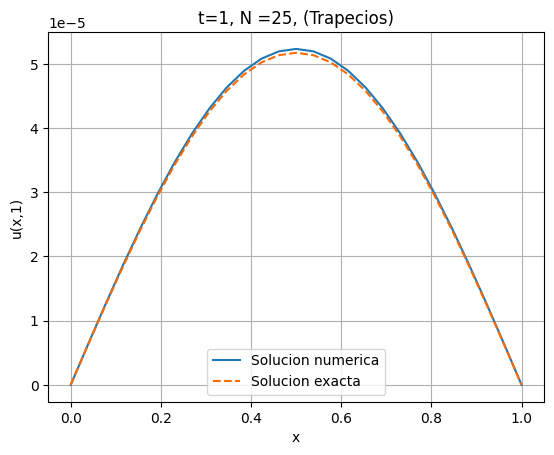

diferencia entre u(0.5,1)-u-exacta(0.5,1) 5.982883298499215e-07


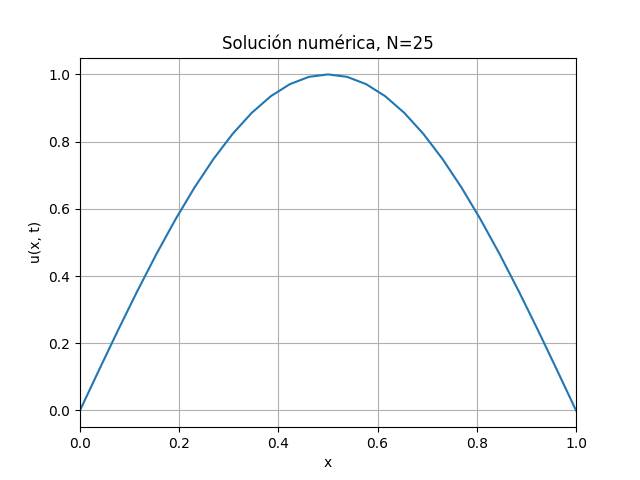

In [41]:
N1=25
Nt1=400
u1,t1,x1=soltrap(N1,Nt1)
u_exacta=np.exp(-np.pi**2*(t1[Nt1-1]))*np.sin(np.pi*x1)
print ("Error relativo entre la solucíon exacta y la obtenida al t=1: ", np.linalg.norm(u_exacta-u1[:,Nt1-1])/np.linalg.norm(u_exacta))
plt.plot(x1,u1[:,Nt1-1] ,  label="Solucion numerica")
plt.plot(x1,u_exacta,linestyle='--', color='#ff6A00', label="Solucion exacta")
plt.grid()
plt.title("t=1, N =25, (Trapecios)")
plt.ylabel("u(x,1)")
plt.xlabel("x")
plt.legend()
plt.show()
print("diferencia entre u(0.5,1)-u-exacta(0.5,1)", u1[13, Nt1-1]-u_exacta[13])
animar_solucion(u1, t1, x1, N1)


Error relativo entre la solucíon exacta y la obtenida al t=1:  0.0010991932638502702


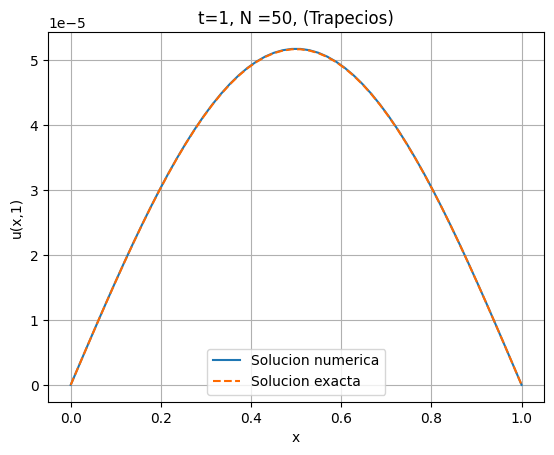

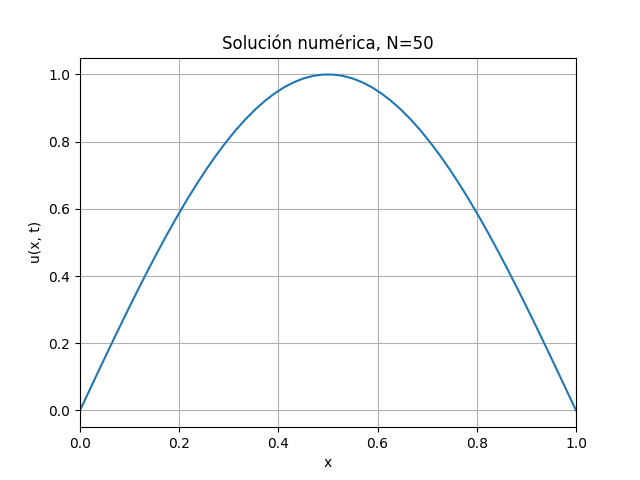

In [42]:
N2=50
Nt2=200
u2,t2,x2=soltrap(N2,Nt2)
u_exacta=np.exp(-np.pi**2*(t2[Nt2-1]))*np.sin(np.pi*x2)
print ("Error relativo entre la solucíon exacta y la obtenida al t=1: ", np.linalg.norm(u_exacta-u2[:,Nt2-1])/np.linalg.norm(u_exacta))
plt.plot(x2,u2[:,Nt2-1] , label="Solucion numerica")
plt.plot(x2,u_exacta,linestyle='--', color='#ff6A00', label="Solucion exacta")
plt.grid()
plt.title("t=1, N =50, (Trapecios)")
plt.ylabel("u(x,1)")
plt.xlabel("x")
plt.legend()
plt.show()

animar_solucion(u2, t2, x2, N2)


Error relativo entre la solucíon exacta y la obtenida al t=1:  0.0012268560725603932


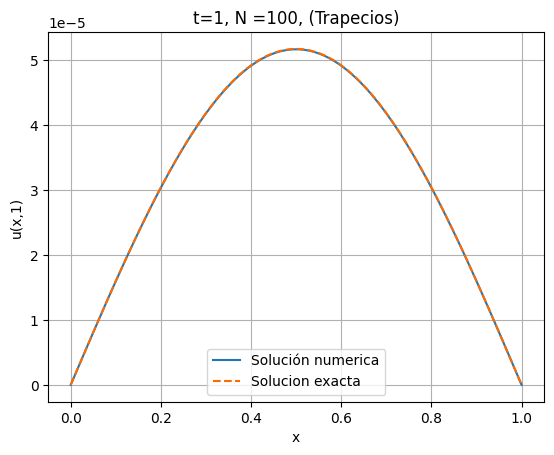

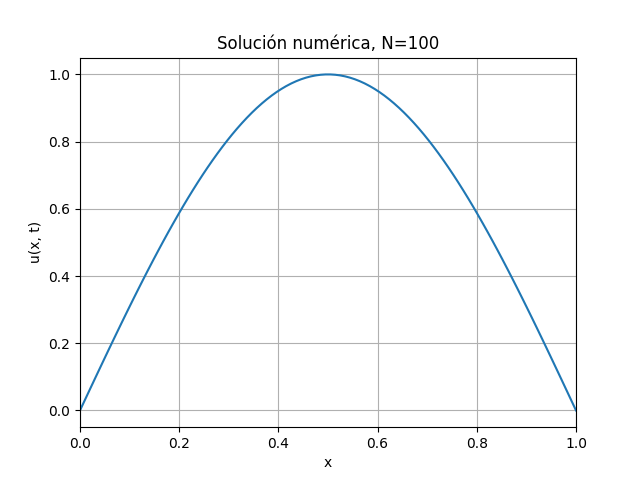

In [43]:
N3=100
Nt3=200
u3,t3,x3=soltrap(N3,Nt3)
u_exacta=np.exp(-np.pi**2*(t3[Nt3-1]))*np.sin(np.pi*x3)
print ("Error relativo entre la solucíon exacta y la obtenida al t=1: ", np.linalg.norm(u_exacta-u3[:,Nt3-1])/np.linalg.norm(u_exacta))
plt.plot(x3,u3[:,Nt3-1] , label="Solución numerica")
plt.plot(x3,u_exacta,linestyle='--', color='#ff6A00', label="Solucion exacta")
plt.grid()
plt.title("t=1, N =100, (Trapecios)")
plt.ylabel("u(x,1)")
plt.xlabel("x")
plt.legend()
plt.show()

animar_solucion(u3, t3, x3, N3)

Error relativo entre la solucíon exacta y la obtenida al t=1:  0.0016662057474613142


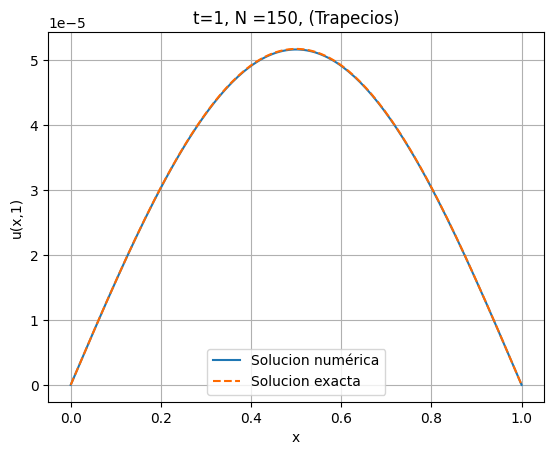

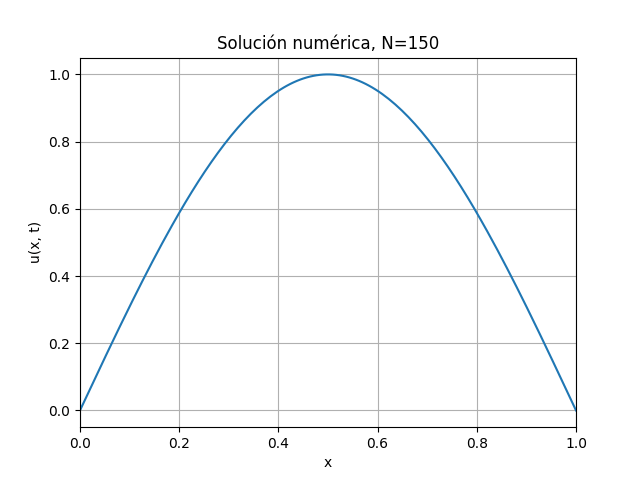

In [46]:
N4=150
Nt4=200
u4,t4,x4=soltrap(N4,Nt4)
u_exacta=np.exp(-np.pi**2*(t4[Nt4-1]))*np.sin(np.pi*x4)
print ("Error relativo entre la solucíon exacta y la obtenida al t=1: ", np.linalg.norm(u_exacta-u4[:,Nt4-1])/np.linalg.norm(u_exacta))
plt.plot(x4,u4[:,Nt4-1] ,label="Solucion numérica")
plt.plot(x4,u_exacta,linestyle='--',color= '#ff6A00', label="Solucion exacta")
plt.grid()
plt.title("t=1, N =150, (Trapecios)")
plt.ylabel("u(x,1)")
plt.xlabel("x")
plt.legend()
plt.show()

animar_solucion(u4, t4, x4, N4)